# Notebook 01 — Dataset Visualization (qualitative sanity-check)

**Paper artifact:** qualitative support for the *Dataset* section — visual verification of the YOLO underwater corrosion annotations (no reported numeric metric).

This notebook loads the underwater dataset images together with their YOLO-format labels and renders the bounding boxes on top of each image, providing a qualitative inspection that complements the quantitative dataset description in the paper. It first summarizes the image-resolution statistics of every split, then draws an annotated mosaic for the training and test partitions so the reader can confirm the labels are geometrically correct and well aligned with the visible corrosion.

**Purpose.** This is a visual integrity check: it confirms that the conversion to YOLO format preserved the correct geometry and that boxes land on the corroded regions. No metric is computed here.

---

| | |
|---|---|
| **Inputs** | `./dataset_yolo/images/{train,test}` and `./dataset_yolo/labels/{train,test}` (YOLO-format `.txt` labels) |
| **Output** | annotated image mosaics (training and test) — qualitative figures, no numeric metric |
| **Environment** | Python 3 (conda `base`) · matplotlib · Pillow · NumPy |

> **Note on outputs.** All code cells and their image outputs are preserved exactly as executed; the rendered mosaics and console logs appear in their original form. Re-running on the same dataset reproduces the same figures.

In [49]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import glob
import numpy as np

### Dataset resolution audit

Before drawing any boxes, scan every split and report how many images it contains and their resolution distribution. A single dominant resolution is expected, since all tiles were exported at a fixed size during dataset preparation.

In [50]:
import os
import glob
from collections import Counter
from PIL import Image
import numpy as np

# Path to the YOLO dataset (adjust if needed)
dataset_path = "./dataset_yolo"

# Image folders
splits = ["train", "valid", "test"]
extensions = ("*.jpg", "*.png", "*.jpeg")

def get_image_sizes(split_path):
    image_files = []
    for ext in extensions:
        image_files.extend(glob.glob(os.path.join(split_path, ext)))
    
    sizes = []
    for img_path in image_files:
        try:
            with Image.open(img_path) as img:
                sizes.append(img.size)  # (width, height)
        except:
            pass
    return sizes

all_sizes = []

for split in splits:
    split_dir = os.path.join(dataset_path, "images", split)
    if os.path.exists(split_dir):
        print(f"\n📁 Analyzing images in: {split.upper()}")
        sizes = get_image_sizes(split_dir)
        all_sizes.extend(sizes)
        counter = Counter(sizes)
        print(f"   🖼️ Total images: {len(sizes)}")
        print(f"   📏 Most common resolutions:")
        for (w, h), count in counter.most_common(5):
            print(f"      {w}x{h} → {count} images")
    else:
        print(f"\n❌ Image folder '{split}' was not found.")

if all_sizes:
    widths, heights = zip(*all_sizes)
    print("\n📊 Global dataset statistics:")
    print(f"   🔹 Minimum resolution: {min(widths)}x{min(heights)}")
    print(f"   🔹 Maximum resolution: {max(widths)}x{max(heights)}")
    print(f"   🔹 Approximate mean resolution: {int(np.mean(widths))}x{int(np.mean(heights))}")
else:
    print("\n⚠️ No images were found to analyze.")



📁 Analyzing images in: TRAIN
   🖼️ Total images: 230
   📏 Most common resolutions:
      640x640 → 230 images

❌ Image folder 'valid' was not found.

📁 Analyzing images in: TEST
   🖼️ Total images: 31
   📏 Most common resolutions:
      640x640 → 31 images

📊 Global dataset statistics:
   🔹 Minimum resolution: 640x640
   🔹 Maximum resolution: 640x640
   🔹 Approximate mean resolution: 640x640


The scan confirms a homogeneous dataset: every image is square and shares a single resolution, so no aspect-ratio distortion is introduced when the tiles are fed to the detector. With the geometry validated, the next sections overlay the YOLO labels to check that the boxes fall on the visible corrosion.

### Path configuration

Define the paths to the image and label folders produced by the dataset-preparation script.

In [51]:
output_root = "./dataset_yolo"

yolo_images_train = os.path.join(output_root, "images", "train")
yolo_labels_train = os.path.join(output_root, "labels", "train")

yolo_images_test  = os.path.join(output_root, "images", "test")
yolo_labels_test  = os.path.join(output_root, "labels", "test")

### Visualization helper

This helper takes an image path and its corresponding label file and draws the YOLO bounding boxes on a matplotlib axis.

In [52]:
def plot_image_with_masks(ax, image_path, label_path):
    # Draw an image and its bounding boxes on a matplotlib axis.
    img = Image.open(image_path)
    ax.imshow(img)
    ax.axis('off')  # Hide the axes

    if not os.path.exists(label_path):
        ax.set_title(os.path.basename(image_path) + "\n(No label)", fontsize=8)
        return

    img_w, img_h = img.size

    with open(label_path, 'r') as f:
        for line in f.readlines():
            parts = list(map(float, line.strip().split()))
            class_id = parts[0]
            # YOLO format: class x_center y_center width height
            if len(parts) >= 5:
                center_x, center_y, bbox_width, bbox_height = parts[1:5]

                # Denormalize coordinates
                x_min = (center_x - bbox_width / 2) * img_w
                y_min = (center_y - bbox_height / 2) * img_h
                width = bbox_width * img_w
                height = bbox_height * img_h

                # Build the rectangle
                rect = patches.Rectangle(
                    (x_min, y_min),
                    width,
                    height,
                    linewidth=1,
                    edgecolor='r',
                    facecolor='none' # No fill for bounding box
                )
                # Add the rectangle to the axis
                ax.add_patch(rect)
    
    ax.set_title(os.path.basename(image_path), fontsize=8)


### Visualization of training images (Train)

Render an annotated mosaic of up to 20 training images. Each red rectangle is a denormalized YOLO bounding box, letting us confirm that the labels are correctly aligned with the corroded regions.

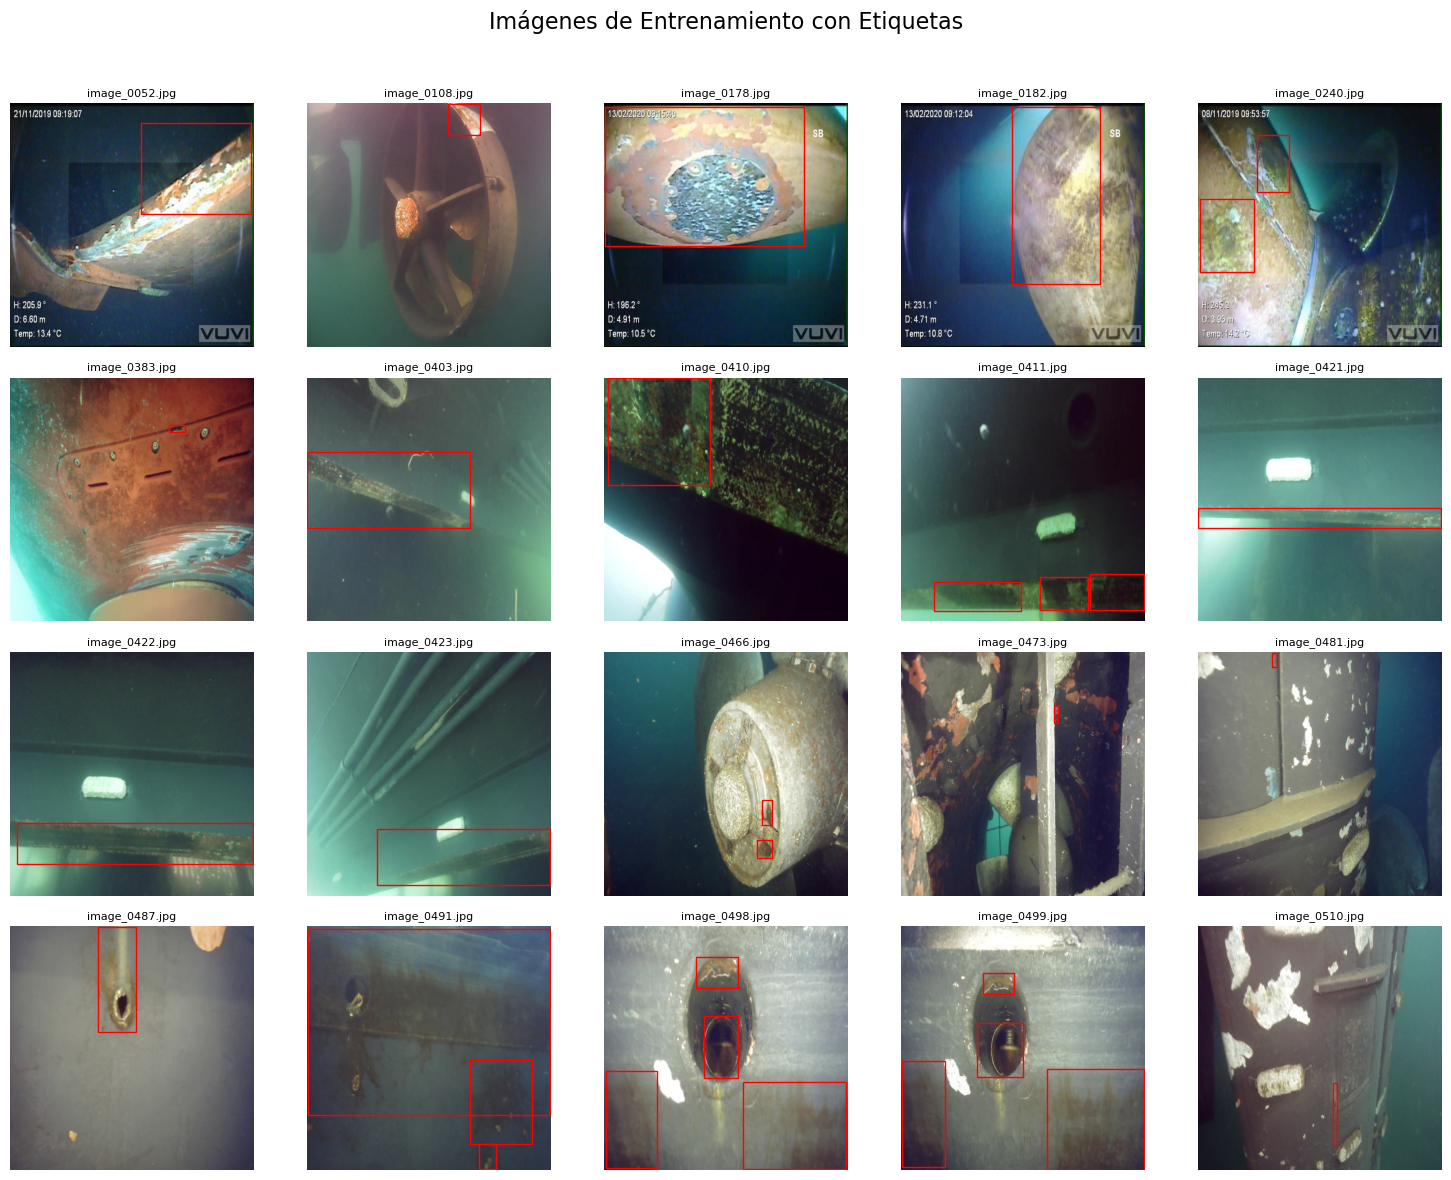

In [53]:
# Get up to 20 label files
train_labels = sorted(glob.glob(os.path.join(yolo_labels_train, '*.txt')))[:20]

# Find the corresponding image for each label, regardless of extension
train_images = []
for label_path in train_labels:
    base_name = os.path.splitext(os.path.basename(label_path))[0]
    # Find any image file with the same base name
    possible_images = glob.glob(os.path.join(yolo_images_train, base_name + '.*'))
    # Filter for common image extensions to be safe
    image_file = next((f for f in possible_images if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))), None)
    
    if image_file:
        train_images.append(image_file)

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
fig.suptitle('Training Images with Labels', fontsize=16)
axes = axes.flatten()

for i, img_path in enumerate(train_images):
    if i >= len(axes):
        break
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(yolo_labels_train, f"{base_name}.txt")
    
    # Check if the image exists before plotting
    if not os.path.exists(img_path):
        axes[i].set_title(f"Not found\n{os.path.basename(img_path)}", fontsize=8, color='red')
        axes[i].axis('off')
        continue
        
    plot_image_with_masks(axes[i], img_path, label_path)

# Hide unused axes
for j in range(len(train_images), len(axes)):
    axes[j].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Visualization of test images (Test)

Same annotated mosaic for the held-out test partition, confirming that the test labels are equally well aligned before the images are used for evaluation.

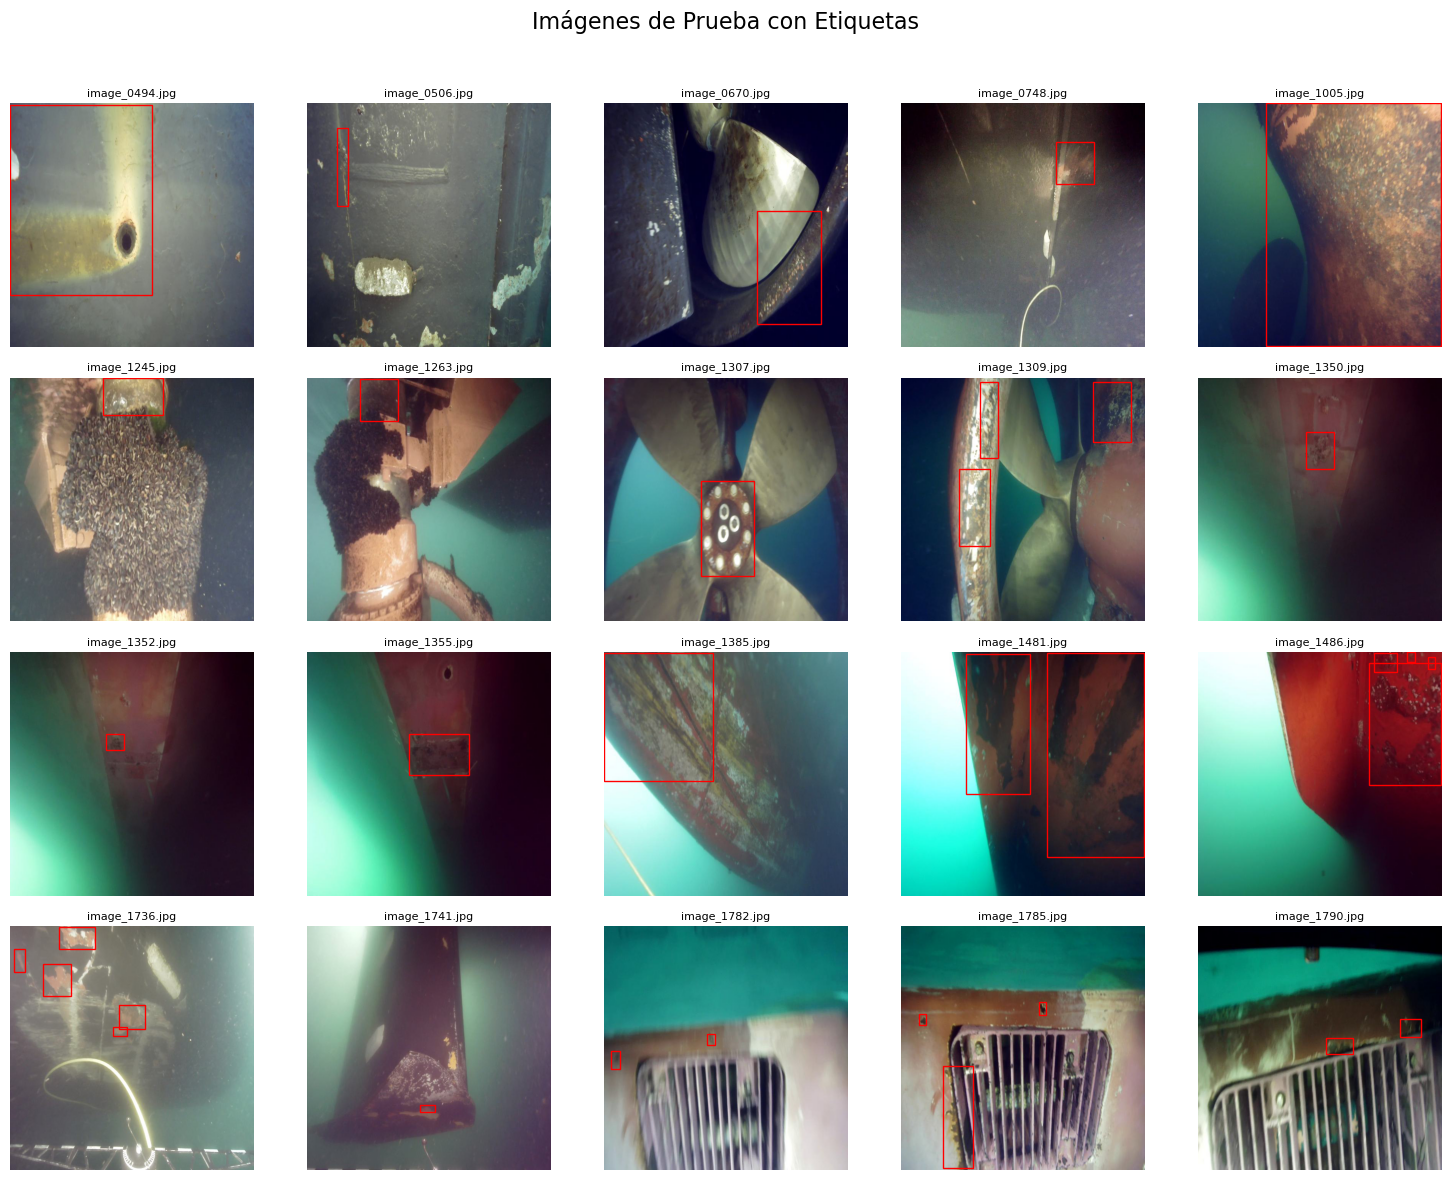

In [54]:
# Get up to 20 label files
test_labels = sorted(glob.glob(os.path.join(yolo_labels_test, '*.txt')))[:20]

# Find the corresponding image for each label, regardless of extension
test_images = []
for label_path in test_labels:
    base_name = os.path.splitext(os.path.basename(label_path))[0]
    # Find any image file with the same base name
    possible_images = glob.glob(os.path.join(yolo_images_test, base_name + '.*'))
    # Filter for common image extensions to be safe
    image_file = next((f for f in possible_images if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))), None)
    
    if image_file:
        test_images.append(image_file)

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
fig.suptitle('Test Images with Labels', fontsize=16)
axes = axes.flatten()

for i, img_path in enumerate(test_images):
    if i >= len(axes):
        break
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(yolo_labels_test, f"{base_name}.txt")
    
    # Check if the image exists before plotting
    if not os.path.exists(img_path):
        axes[i].set_title(f"Not found\n{os.path.basename(img_path)}", fontsize=8, color='red')
        axes[i].axis('off')
        continue
        
    plot_image_with_masks(axes[i], img_path, label_path)

# Hide unused axes
for j in range(len(test_images), len(axes)):
    axes[j].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()